<a href="https://colab.research.google.com/github/NadiyaNowshin/People-Flow-Detection-and-Tracking-with-YOLO-and-Heatmap-Visualization/blob/main/people_flow_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# People Flow Detection using Object Tracking & Heatmap Visualization

**Pipeline:** YOLOv8 (person detection) → ByteTrack (persistent IDs) → two-line IN/OUT counting → motion heatmap.

> Tip: `Runtime → Change runtime type → T4 GPU` makes this much faster. Then run all cells top to bottom.

## 1. Install & imports

In [1]:
!pip -q install ultralytics

In [3]:
import os, urllib.request
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO

VIDEO_URL = "https://media.roboflow.com/supervision/video-examples/people-walking.mp4"
INPUT_VIDEO = "people-walking.mp4"

if not os.path.exists(INPUT_VIDEO):
    urllib.request.urlretrieve(VIDEO_URL, INPUT_VIDEO)

cap = cv2.VideoCapture(INPUT_VIDEO)
W   = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
H   = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
FPS = cap.get(cv2.CAP_PROP_FPS)
N   = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
ok , first_frame = cap.read()
cap.release()
print(f"Resolution: {W}x{H} | FPS: {FPS:.1f} | Frames: {N}")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Resolution: 1920x1080 | FPS: 25.0 | Frames: 341


## 2. Define the two lines

The lines are horizontal, so each one is just a **y-coordinate**.

- **Upper line** (green) → used for **IN** (person moving *down* across it)
- **Lower line** (red) → used for **OUT** (person moving *up* across it)

Get your own coordinates from https://polygonzone.roboflow.com/ : upload the first frame, draw the two lines, and copy the y-values here.
The defaults below are placeholders (40% and 65% of the frame height). Run the next cell, look at the preview, and adjust until the lines sit where you want them.

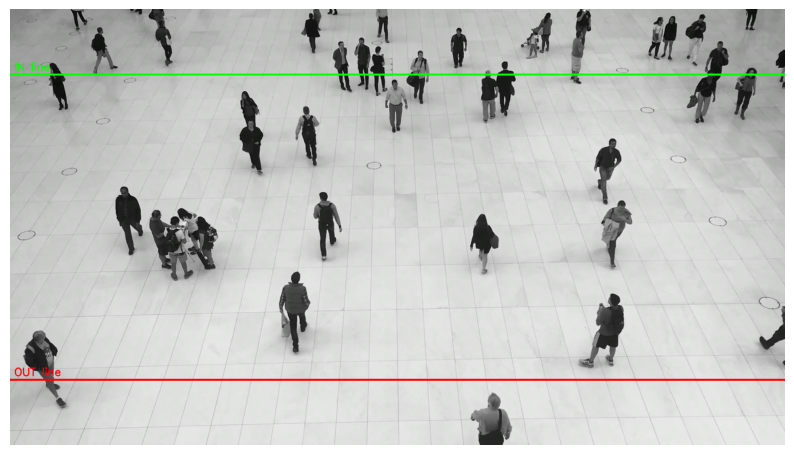

LINE_TOP_Y = 162 | LINE_BOTTOM_Y = 918


In [4]:
# ---- Editable Value (pixel y-values) ----
LINE_TOP_Y    = int(H * 0.15)   # upper line  -> IN
LINE_BOTTOM_Y = int(H * 0.85)   # lower line  -> OUT
# --------------------------------------

IN_COLOR  = (0, 255, 0)    # green  (BGR)
OUT_COLOR = (0, 0, 255)    # red    (BGR)

preview = first_frame.copy()

#Draw the two lines
cv2.line(preview, (0, LINE_TOP_Y),    (W, LINE_TOP_Y),    IN_COLOR,  3)
cv2.line(preview, (0, LINE_BOTTOM_Y), (W, LINE_BOTTOM_Y), OUT_COLOR, 3)

#Add text labels
cv2.putText(preview, "IN line",  (10, LINE_TOP_Y - 10),    cv2.FONT_HERSHEY_SIMPLEX, 0.9, IN_COLOR,  2)
cv2.putText(preview, "OUT line", (10, LINE_BOTTOM_Y - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.9, OUT_COLOR, 2)

plt.figure(figsize=(10, 6));
plt.imshow(cv2.cvtColor(preview, cv2.COLOR_BGR2RGB));
plt.axis("off");
plt.show()
print("LINE_TOP_Y =", LINE_TOP_Y, "| LINE_BOTTOM_Y =", LINE_BOTTOM_Y)

## 3. Detect, track, count, build heatmap

- **Detection:** YOLOv8 pre-trained on COCO, `classes=[0]` keeps only *person*.
- **Tracking:** ByteTrack (built into Ultralytics) keeps one ID per person across frames.
- **Memory:** `prev_center` is a dictionary `{track_id: (cx, cy)}` of each person's position in the previous frame.
- **Counting:**
  - **IN**: previous center above the upper line and current center on/below it (moving down).
  - **OUT**: previous center below the lower line and current center on/above it (moving up).
  - Each ID is counted at most once per direction (`counted_in` / `counted_out` sets).
- **Heatmap:** every frame, each bounding-box center adds +1 to a 2D accumulator.

In [6]:
model = YOLO("yolov8s.pt")      # try yolov8s.pt / yolov8m.pt for better accuracy

cap = cv2.VideoCapture(INPUT_VIDEO)
writer = cv2.VideoWriter("output_raw.mp4", cv2.VideoWriter_fourcc(*"mp4V"), FPS, (W, H))

prev_center = {}                   # {track_id: (cx, cy)}
counted_in , counted_out = set(), set()
heat = np.zeros((H,W), dtype=np.float32)

frame_idx = 0
while True:
    ok, frame = cap.read()
    if not ok:
        break
    frame_idx += 1

    results = model.track(frame, persist=True, tracker="bytetrack.yaml",
                          classes=[0], conf=0.3, verbose=False)[0]

    if results.boxes.id is not None:

        #Extract boxes and IDs
        boxes = results.boxes.xyxy.cpu().numpy().astype(int)
        ids   = results.boxes.id.cpu().numpy().astype(int)

        for (x1, y1, x2, y2), tid in zip(boxes, ids):

            #Find the center
            cx, cy = (x1 + x2) // 2, (y1 + y2) // 2

            # heatmap accumulation (clip so we never index out of bounds)
            heat[min(max(cy, 0), H - 1), min(max(cx, 0), W - 1)] += 1

            # direction / line-crossing logic
            if tid in prev_center:
                py = prev_center[tid][1]
                if py < LINE_TOP_Y <= cy and tid not in counted_in:          # moving DOWN across upper line
                    counted_in.add(tid)
                if py > LINE_BOTTOM_Y >= cy and tid not in counted_out:      # moving UP across lower line
                    counted_out.add(tid)
            prev_center[tid] = (cx, cy)

            # draw box, ID and center
            cv2.rectangle(frame, (x1, y1), (x2, y2), (255, 200, 0), 2)
            cv2.putText(frame, f"ID {tid}", (x1, max(y1 - 8, 15)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 200, 0), 2)
            cv2.circle(frame, (cx, cy), 4, (0, 255, 255), -1)

    # lines
    cv2.line(frame, (0, LINE_TOP_Y),    (W, LINE_TOP_Y),    IN_COLOR,  3)
    cv2.line(frame, (0, LINE_BOTTOM_Y), (W, LINE_BOTTOM_Y), OUT_COLOR, 3)

    # live counters
    cv2.rectangle(frame, (10, 10), (230, 90), (0, 0, 0), -1)
    cv2.putText(frame, f"IN : {len(counted_in)}",  (20, 42), cv2.FONT_HERSHEY_SIMPLEX, 0.9, IN_COLOR,  2)
    cv2.putText(frame, f"OUT: {len(counted_out)}", (20, 78), cv2.FONT_HERSHEY_SIMPLEX, 0.9, OUT_COLOR, 2)

    #Save the frame
    writer.write(frame)

cap.release(); writer.release()
print(f"Processed {frame_idx} frames | IN = {len(counted_in)} | OUT = {len(counted_out)}")

Processed 341 frames | IN = 13 | OUT = 8


## 4. Make the video browser-playable & show it

In [7]:
!ffmpeg -y -loglevel error -i output_raw.mp4 -vcodec libx264 -pix_fmt yuv420p output_people_flow.mp4

from IPython.display import HTML
from base64 import b64encode
data = b64encode(open("output_people_flow.mp4", "rb").read()).decode()
HTML(f'<video width=800 controls><source src="data:video/mp4;base64,{data}" type="video/mp4"></video>')

## 5. Final heatmap

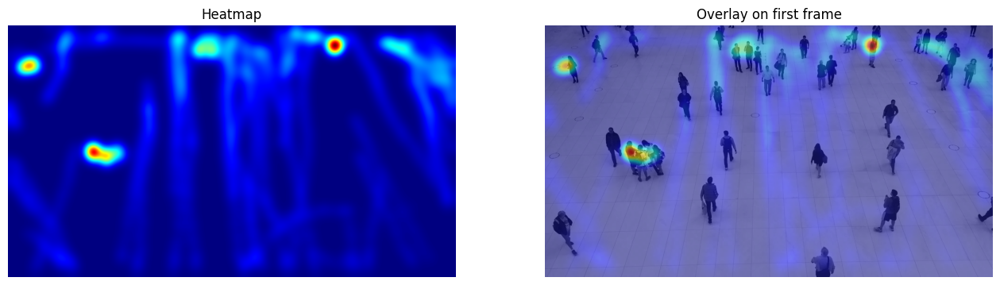

In [ ]:
blur = cv2.GaussianBlur(heat, (0, 0), sigmaX=25)
norm = cv2.normalize(blur, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
heat_color = cv2.applyColorMap(norm, cv2.COLORMAP_JET)
overlay = cv2.addWeighted(first_frame, 0.5, heat_color, 0.5, 0)

cv2.imwrite("heatmap.png", heat_color)
cv2.imwrite("heatmap_overlay.png", overlay)

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
ax[0].imshow(cv2.cvtColor(heat_color, cv2.COLOR_BGR2RGB)); ax[0].set_title("Heatmap"); ax[0].axis("off")
ax[1].imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB));    ax[1].set_title("Overlay on first frame"); ax[1].axis("off")
plt.show()

## 6. Download results

In [ ]:
from google.colab import files
files.download("output_people_flow.mp4")
files.download("heatmap.png")
files.download("heatmap_overlay.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# README

## Detection method
- **Model:** YOLOv8n (Ultralytics, COCO pre-trained), filtered to class `0` (person), confidence threshold 0.3.
- **Tracker:** ByteTrack via `model.track(..., tracker="bytetrack.yaml", persist=True)`, which gives each person a persistent ID across frames.
- **Position used:** the center of each bounding box, `(cx, cy) = ((x1+x2)/2, (y1+y2)/2)`. A dictionary `prev_center = {id: (cx, cy)}` stores each ID's position from the previous frame.

## Line coordinates
Frame size is printed in step 1. Lines are full-width horizontal lines (drawn from x=0 to x=frame width):

| Line | Colour | y-coordinate |
|---|---|---|
| Upper (IN) | Green | `LINE_TOP_Y` = *162* |
| Lower (OUT) | Red | `LINE_BOTTOM_Y` = *918* |

Coordinates were chosen using https://polygonzone.roboflow.com/ on the first video frame.

## IN / OUT logic
- **IN:** a person's previous center `y` was above the upper line and the current center `y` is on or below it (`prev_y < LINE_TOP_Y <= cy`), meaning they came from the top and crossed the upper line going down.
- **OUT:** previous center `y` was below the lower line and the current center `y` is on or above it (`prev_y > LINE_BOTTOM_Y >= cy`), meaning they came from the bottom and crossed the lower line going up.
- Each track ID is stored in a set, so one person is counted at most once per direction even if the tracker jitters around the line.

## Heatmap
Each frame, every bounding-box center adds 1 to a 2D array the size of the frame. At the end the array is Gaussian-blurred, normalised to 0-255, colour-mapped (JET) and saved as `heatmap.png`, plus a 50/50 overlay on the first frame as `heatmap_overlay.png`. Red/yellow means high presence, blue means low.

## Outputs
`output_people_flow.mp4`, `heatmap.png`, `heatmap_overlay.png`